# Introduction to Machine Translation (MT):

Machine Translation is a subfield of AI and linguistics that develops systems capable of translating text from one language to another. The primary goal of machine translation is to enable effective communication between people who speak different languages by automating the process of language translation.

**Student Name:** Faisal AL Zahrani  
**Student ID:** 2230000363  
**Section:** 9MA1  
**Course:** ARTI 501 — Natural Language Processing  

> **Lab 10 solution** — The instructor's original lesson, images, explanations, and example code have been preserved. Only the task answers and an optional environment compatibility setup were added.

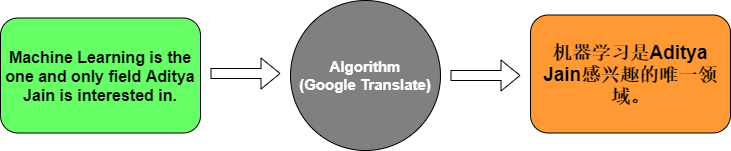

Challenges in Machine Translation:
- Ambiguity

Ex. I went to the bank.
- Idiomatic Expressions

Ex. It's raining cats and dogs.
- Low-Resource Languages

Some languages have very limited data.

Applications of Machine Translation:
- Global Business and E-commerce
-Cross-Cultural Communication
- Multilingual Content Creation
- Language Learning



## Neural Machine Translation:

Neural Machine Translation is a data-driven approach where a single large neural network learns to represent both the source language and the target language, and to directly map between them.
Instead of using manually defined rules or phrase tables, it learns translation patterns automatically from large datasets of bilingual text.

### Key Components of Neural Machine Translation:

<img src="https://drive.google.com/thumbnail?id=1xMmuMvOaYI73cYhQ1lbE5pIjDPWXhfgq&sz=w1000" width="600">


### Environment check (only for compatibility)

The original TensorFlow example below remains unchanged. If TensorFlow is missing, this setup uses **Keras 3 + PyTorch** to execute it locally; on Google Colab it uses TensorFlow. The fallback is solely for the three-sentence instructional example.

In [1]:
# Optional compatibility: preserve the instructor's original TensorFlow code.
# On Colab/TensorFlow installations, the cells below use TensorFlow unchanged.
# On an offline machine without TensorFlow, Keras 3 + PyTorch runs the same example.
import os, sys, types, re
import importlib.util
import numpy as np

if importlib.util.find_spec("tensorflow") is None:
    os.environ["KERAS_BACKEND"] = "torch"
    os.environ.setdefault("OMP_NUM_THREADS", "1")
    import torch
    torch.set_num_threads(1)
    import keras as _keras
    from collections import Counter

    class Tokenizer:  # Small legacy Tokenizer equivalent, only for the lab's sample.
        def __init__(self, *args, **kwargs):
            self.word_index = {}
            self.index_word = {}
            self.word_counts = Counter()
        def _tokens(self, sentence):
            return re.findall(r"\b\w+\b", str(sentence).lower(), flags=re.UNICODE)
        def fit_on_texts(self, texts):
            for sentence in texts:
                self.word_counts.update(self._tokens(sentence))
            words = sorted(self.word_counts, key=lambda w: -self.word_counts[w])
            self.word_index = {word: i+1 for i, word in enumerate(words)}
            self.index_word = {i: word for word, i in self.word_index.items()}
        def texts_to_sequences(self, texts):
            return [[self.word_index[word] for word in self._tokens(sentence)
                     if word in self.word_index] for sentence in texts]
        def sequences_to_texts(self, sequences):
            return [" ".join(self.index_word.get(int(index), "") for index in seq
                             if int(index) != 0).strip() for seq in sequences]

    def pad_sequences(sequences, maxlen=None, dtype="int32", padding="pre",
                      truncating="pre", value=0):
        maxlen = maxlen or max(map(len, sequences))
        out = np.full((len(sequences), maxlen), value, dtype=dtype)
        for index, seq in enumerate(sequences):
            seq = list(seq)
            if len(seq) > maxlen:
                seq = seq[-maxlen:] if truncating == "pre" else seq[:maxlen]
            if seq:
                if padding == "pre": out[index, -len(seq):] = seq
                else: out[index, :len(seq)] = seq
        return out

    class _CompatibleSequential(_keras.Sequential):
        # Keras/Torch sparse loss requires (N, T), but old TF code supplies (N, T, 1).
        @staticmethod
        def _fix_labels(y):
            a = np.asarray(y)
            return a.squeeze(axis=-1) if a.ndim == 3 and a.shape[-1] == 1 else y
        def fit(self, x, y=None, *args, **kwargs):
            return super().fit(x, self._fix_labels(y), *args, **kwargs)
        def evaluate(self, x, y=None, *args, **kwargs):
            return super().evaluate(x, self._fix_labels(y), *args, **kwargs)

    _tensorflow = types.ModuleType("tensorflow")
    _tensorflow._lab10_shim = True
    _tfkeras = types.ModuleType("tensorflow.keras")
    _tfkeras.Sequential = _CompatibleSequential
    _tfkeras.layers = _keras.layers
    _tfkeras.Model = _keras.Model
    _tfkeras.optimizers = _keras.optimizers
    _tfkeras.callbacks = _keras.callbacks
    _tfkeras.utils = _keras.utils
    _tfkeras.preprocessing = types.ModuleType("tensorflow.keras.preprocessing")
    _text = types.ModuleType("tensorflow.keras.preprocessing.text")
    _seq = types.ModuleType("tensorflow.keras.preprocessing.sequence")
    _text.Tokenizer = Tokenizer
    _seq.pad_sequences = pad_sequences
    _tensorflow.keras = _tfkeras
    for _m in (_tensorflow, _tfkeras, _tfkeras.preprocessing, _text, _seq):
        sys.modules[_m.__name__] = _m
    print("Environment: TensorFlow not installed; using Keras 3 / PyTorch compatibility for the original example.")
else:
    print("Environment: TensorFlow available; using instructor's original code.")

Environment: TensorFlow not installed; using Keras 3 / PyTorch compatibility for the original example.


In [2]:
#!pip install tensorflow

In [3]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
import numpy as np

# Example bilingual dataset
english_sentences = ["Hello.", "How are you?", "This is a machine translation example."]
french_sentences = ["Bonjour.", "Comment ça va?", "Ceci est un exemple de traduction automatique."]

# Tokenize the english sentences
tokenizer_eng = Tokenizer()
tokenizer_eng.fit_on_texts(english_sentences) # Tokenize words and assign an integer ID to each unique word
eng_sequences = tokenizer_eng.texts_to_sequences(english_sentences) # Returns a list of tokens replaced by their index. Note: words index will start from 1 because 0 is reserved by default for padding (not assigned to any word).
print(f"eng_sequences = {eng_sequences}")
eng_word_index = tokenizer_eng.word_index # Returns the dictionary created by the tokenizer dict {word: index}.
print(f"eng_word_index = {eng_word_index}")

eng_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10]]
eng_word_index = {'hello': 1, 'how': 2, 'are': 3, 'you': 4, 'this': 5, 'is': 6, 'a': 7, 'machine': 8, 'translation': 9, 'example': 10}


In [4]:
# Tokenize the french sentences
tokenizer_frn = Tokenizer()
tokenizer_frn.fit_on_texts(french_sentences)
frn_sequences = tokenizer_frn.texts_to_sequences(french_sentences)

print(f"frn_sequences = {frn_sequences}")
frn_word_index = tokenizer_frn.word_index
print(f"frn_word_index = {frn_word_index}")

frn_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10, 11]]
frn_word_index = {'bonjour': 1, 'comment': 2, 'ça': 3, 'va': 4, 'ceci': 5, 'est': 6, 'un': 7, 'exemple': 8, 'de': 9, 'traduction': 10, 'automatique': 11}


In [5]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Padding sequences
eng_padded = pad_sequences(eng_sequences) # makes all sequences the same length by padding with zeros at the beginning (default)
print(f"eng_padded = {eng_padded}")

eng_padded = [[ 0  0  0  0  0  1]
 [ 0  0  0  2  3  4]
 [ 5  6  7  8  9 10]]


In [6]:
frn_padded = pad_sequences(frn_sequences)
frn_padded

array([[ 0,  0,  0,  0,  0,  0,  1],
       [ 0,  0,  0,  0,  2,  3,  4],
       [ 5,  6,  7,  8,  9, 10, 11]], dtype=int32)

## LSTM Model

<img src="https://drive.google.com/uc?export=view&id=1rUaLO1wEOcUZ10Kwd0nUvS3jQzrqoOcI" width="550">

In [7]:
from sklearn.model_selection import train_test_split

# Train-test split
eng_train, eng_test, frn_train, frn_test = train_test_split(eng_padded, frn_padded, test_size=0.2, random_state=42)

# Define the model
model = tf.keras.Sequential([
    tf.keras.layers.Embedding(input_dim=len(eng_word_index) + 1, output_dim=64),
    tf.keras.layers.LSTM(64),
    tf.keras.layers.RepeatVector(frn_padded.shape[1]), #length of french sentence
    tf.keras.layers.LSTM(64, return_sequences=True),
    tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(len(frn_word_index) + 1, activation='softmax')) #convert to probabilities for each frn word
])

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Train the model
model.fit(eng_train, np.expand_dims(frn_train, -1), epochs=50, batch_size=1, validation_split=0.2)

# Evaluate the model
loss, accuracy = model.evaluate(eng_test, np.expand_dims(frn_test, -1))
print(f'Test Accuracy: {accuracy}')

Epoch 1/50


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.0000e+00 - loss: 2.4848

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step - accuracy: 0.0000e+00 - loss: 2.4848 - val_accuracy: 0.0000e+00 - val_loss: 2.4866


Epoch 2/50


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.5714 - loss: 2.4765

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - accuracy: 0.5714 - loss: 2.4765 - val_accuracy: 0.0000e+00 - val_loss: 2.4887


... (143 outputs left out)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - accuracy: 0.8571 - loss: 0.5087 - val_accuracy: 0.0000e+00 - val_loss: 6.0708


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.5714 - loss: 1.6906

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.5714 - loss: 1.6906


Test Accuracy: 0.5714285969734192


In [8]:
# Inference
def translate_sentence(sentence, model, eng_tokenizer, frn_tokenizer):
    sequence = eng_tokenizer.texts_to_sequences([sentence])
    padded_sequence = pad_sequences(sequence, maxlen=eng_padded.shape[1])
    predicted_sequence = model.predict(padded_sequence) #outputs probabilities for each timestep (french padded sentence) and each unique word in the target vocabulary.
    translated_sequence = np.argmax(predicted_sequence, axis=-1) #Returns the index (word ID) with the largest value at each timestep.
    translated_sentence = frn_tokenizer.sequences_to_texts(translated_sequence)
    return translated_sentence[0]

# Example Inference
input_sentence = "How are you?"
translated_sentence = translate_sentence(input_sentence, model, tokenizer_eng, tokenizer_frn)
print(f'Input: {input_sentence}\nTranslation: {translated_sentence}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step


Input: How are you?
Translation: comment ça va


________________________________________________________________________________________________________________________________________

### Task 1: Understanding the Model Layers

Answer these simple questions in your own words:

1. What does the **Embedding** layer do to a word index?
3. What is the role of the **Encoder LSTM**?
5. What does the **Decoder LSTM** do?
8. Why do we use `softmax` in the final layer?


#### Task 1 — Answers

**1. What does the Embedding layer do to a word index?**  
It converts a word's integer ID into a dense vector of learned numbers. During training, these vectors are updated so the model can represent useful patterns about words instead of treating them as unrelated IDs.

**3. What is the role of the Encoder LSTM?**  
The Encoder LSTM reads the English input sequence and summarizes its context into hidden and cell states. These states give the decoder information about the source sentence.

**5. What does the Decoder LSTM do?**  
The Decoder LSTM uses the encoder's context to generate a sequence of representations for the French translation. The final output layer turns those representations into word probabilities at each step.

**8. Why do we use `softmax` in the final layer?**  
`softmax` turns the output scores for all possible French words into probabilities that sum to 1. The model selects a word with the highest probability at each position during greedy prediction.

### Task 2:

 Use Case: Language Translation (English-French)

A global e-commerce company wants to expand its reach to French-speaking customers and provide a seamless shopping experience. The company needs a language translation solution to automatically translate product listings, customer reviews, and other relevant content from English to French.

link: https://www.kaggle.com/datasets/devicharith/language-translation-englishfrench

#### Task 2 — Implementation (English → French E-commerce Translation)

**Approach:** clean bilingual English–French pairs, build vocabularies using training data only, prepare source and shifted target tokens, then train an **Encoder–Decoder LSTM**. Evaluate with masked token accuracy and print several product/order/shipping translation examples.

The linked Kaggle corpus is the preferred data source. If no network or dataset is available, the program explicitly runs a **small built-in demo**, so the results must *not* be presented as scores on the Kaggle dataset.

Dataset: https://www.kaggle.com/datasets/devicharith/language-translation-englishfrench

In [9]:
# Change these values to control training time.
DATASET_SLUG = "devicharith/language-translation-englishfrench"
MAX_ROWS = int(os.getenv("LAB10_MAX_ROWS", "5000"))
MAX_ENGLISH_TOKENS = 14
MAX_FRENCH_TOKENS = 15
MAX_EN_VOCAB = 3500
MAX_FR_VOCAB = 4500
EMBEDDING_DIM = 64
HIDDEN_UNITS = 64
BATCH_SIZE = 64
EPOCHS = int(os.getenv("LAB10_EPOCHS", "6"))
USE_DEMO_DATA = os.getenv("LAB10_USE_DEMO", "0") == "1"

# A small, plainly identified offline fallback (not the Kaggle corpus).
DEMO_PAIRS = [
    ("Hello.", "Bonjour."), ("Good morning.", "Bonjour."),
    ("Thank you.", "Merci."), ("Goodbye.", "Au revoir."),
    ("How are you?", "Comment allez vous ?"), ("I am fine.", "Je vais bien."),
    ("Please help me.", "Aidez moi s'il vous plaît."),
    ("Where is my order?", "Où est ma commande ?"),
    ("I need help.", "J'ai besoin d'aide."),
    ("This product is new.", "Ce produit est nouveau."),
    ("The product is available.", "Le produit est disponible."),
    ("The product is not available.", "Le produit n'est pas disponible."),
    ("The price is low.", "Le prix est bas."),
    ("The price is high.", "Le prix est élevé."),
    ("This is a good price.", "C'est un bon prix."),
    ("What is the price?", "Quel est le prix ?"),
    ("I like this product.", "J'aime ce produit."),
    ("I love this product.", "J'adore ce produit."),
    ("I want to buy this.", "Je veux acheter ceci."),
    ("Can I buy this?", "Puis je acheter ceci ?"),
    ("The order is ready.", "La commande est prête."),
    ("Your order is ready.", "Votre commande est prête."),
    ("My order is late.", "Ma commande est en retard."),
    ("The delivery is fast.", "La livraison est rapide."),
    ("The delivery is slow.", "La livraison est lente."),
    ("Delivery is free.", "La livraison est gratuite."),
    ("Free shipping.", "Livraison gratuite."),
    ("I need a refund.", "Je veux un remboursement."),
    ("Can I return this?", "Puis je retourner ceci ?"),
    ("The package has arrived.", "Le colis est arrivé."),
    ("The package is missing.", "Le colis est manquant."),
    ("I paid today.", "J'ai payé aujourd'hui."),
    ("The item is damaged.", "L'article est endommagé."),
    ("The item is perfect.", "L'article est parfait."),
    ("I want a discount.", "Je veux une réduction."),
    ("Is there a discount?", "Y a t il une réduction ?"),
    ("This size is too small.", "Cette taille est trop petite."),
    ("This size is too big.", "Cette taille est trop grande."),
    ("I need another size.", "J'ai besoin d'une autre taille."),
    ("This color is beautiful.", "Cette couleur est belle."),
    ("It is very expensive.", "C'est très cher."),
    ("It is very cheap.", "C'est très bon marché."),
    ("Send me the invoice.", "Envoyez moi la facture."),
    ("I received the invoice.", "J'ai reçu la facture."),
    ("My payment failed.", "Mon paiement a échoué."),
    ("My payment succeeded.", "Mon paiement a réussi."),
    ("The customer is happy.", "Le client est content."),
    ("The customer is unhappy.", "Le client est mécontent."),
    ("The quality is good.", "La qualité est bonne."),
    ("The quality is poor.", "La qualité est mauvaise."),
    ("I recommend this store.", "Je recommande ce magasin."),
    ("I do not recommend this store.", "Je ne recommande pas ce magasin."),
    ("The shop is open.", "Le magasin est ouvert."),
    ("The shop is closed.", "Le magasin est fermé."),
    ("Please check the order.", "Veuillez vérifier la commande."),
    ("Please send the product.", "Veuillez envoyer le produit."),
    ("I need it tomorrow.", "J'en ai besoin demain."),
    ("It will arrive tomorrow.", "Il arrivera demain."),
    ("This is my address.", "Voici mon adresse."),
    ("Enter your address.", "Entrez votre adresse."),
]


def read_bilingual_csv(file_path):
    """Read Kaggle CSV/TSV or ManyThings-style TSV; return standardized columns."""
    file_path = Path(file_path)
    for encoding in ("utf-8-sig", "latin-1"):
        try:
            if file_path.suffix.lower() in (".tsv", ".txt"):
                # .txt corpora often have English, French, attribution columns.
                frame = pd.read_csv(file_path, sep="\t", header=None, encoding=encoding,
                                    on_bad_lines="skip", engine="python")
            else:
                frame = pd.read_csv(file_path, encoding=encoding, low_memory=False,
                                    on_bad_lines="skip")
            break
        except (UnicodeError, pd.errors.ParserError):
            continue
    else:
        raise ValueError(f"Cannot read dataset: {file_path}")
    frame = frame.loc[:, ~frame.columns.astype(str).str.lower().str.startswith("unnamed")]
    if frame.shape[1] < 2:
        raise ValueError("Dataset needs at least two text columns")
    columns = list(frame.columns)
    english = next((c for c in columns if 'english' in str(c).lower() or str(c).lower() in ('en', 'eng')), None)
    french = next((c for c in columns if 'french' in str(c).lower() or str(c).lower() in ('fr', 'fra')), None)
    if english is None or french is None or english == french:
        english, french = columns[:2]  # Kaggle's bilingual CSV order: English then French.
    return frame[[english, french]].rename(columns={english: "english", french: "french"})


def get_data():
    if USE_DEMO_DATA:
        print("DEMO MODE: explicitly selected offline sample (not Kaggle).")
        return pd.DataFrame(DEMO_PAIRS, columns=["english", "french"]), "BUILT-IN DEMO"
    local_path = os.environ.get("LAB10_DATASET_PATH", "").strip()
    if local_path:
        print("Reading local dataset from:", local_path)
        return read_bilingual_csv(local_path), f"LOCAL DATASET: {Path(local_path).name}"
    try:
        import kagglehub
        dataset_dir = Path(kagglehub.dataset_download(DATASET_SLUG))
        files = sorted(dataset_dir.rglob("*.csv")) + sorted(dataset_dir.rglob("*.tsv")) + sorted(dataset_dir.rglob("*.txt"))
        if not files:
            raise FileNotFoundError(f"No CSV/TSV/TXT found in {dataset_dir}")
        for path in files:
            try:
                result = read_bilingual_csv(path)
                if len(result) >= 50:
                    print("Loaded Kaggle file:", path)
                    return result, f"KAGGLE: {path.name}"
            except Exception as exc:
                print("Skipping", path.name, ":", exc)
        raise ValueError("No suitable bilingual file in Kaggle download")
    except Exception as exc:
        print("Kaggle dataset unavailable:", repr(exc))
        print("WARNING: using the small DEMO sample; results are NOT Kaggle results.")
        return pd.DataFrame(DEMO_PAIRS, columns=["english", "french"]), "BUILT-IN DEMO (Kaggle unavailable)"

### Task 2 helper functions: tokenization, vocabularies and padding

In [10]:
import os
import re
import random
import unicodedata
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

english_sentences = ["Hello.", "How are you?", "This is a machine translation example."]
french_sentences = ["Bonjour.", "Comment ça va?", "Ceci est un exemple de traduction automatique."]

def tokenize(text):
    text = unicodedata.normalize("NFKC", str(text)).lower().strip()
    # Unicode-aware words; punctuation is separated into individual tokens.
    return re.findall(r"\w+|[^\w\s]", text, flags=re.UNICODE)

SPECIAL_TOKENS = ["<pad>", "<unk>", "<sos>", "<eos>"]
PAD, UNK, SOS, EOS = 0, 1, 2, 3

def build_vocab(texts, max_words=5000):
    counts = Counter(tok for sentence in texts for tok in tokenize(sentence))
    vocab = dict((tok, index) for index, tok in enumerate(SPECIAL_TOKENS))
    for word, _ in counts.most_common(max(0, max_words - len(SPECIAL_TOKENS))):
        if word not in vocab:
            vocab[word] = len(vocab)
    return vocab

def encode_sentence(text, vocab, add_sos=False, add_eos=False):
    indices = [vocab.get(token, UNK) for token in tokenize(text)]
    return ([SOS] if add_sos else []) + indices + ([EOS] if add_eos else [])

def pad_post(sequences, max_length):
    arr = np.zeros((len(sequences), max_length), dtype=np.int32)
    for i, seq in enumerate(sequences):
        arr[i, :min(len(seq), max_length)] = seq[:max_length]
    return arr



### 2.1 Model dependencies

In [11]:
# Uncomment in Google Colab if needed:
# %pip install -q tensorflow kagglehub pandas scikit-learn matplotlib

# Reuse the environment selected above; no changes to original lesson cells.
if getattr(tf, "_lab10_shim", False):
    import keras
    BACKEND = "PyTorch (Keras 3)"
else:
    keras = tf.keras
    BACKEND = "TensorFlow"

from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

if BACKEND == "PyTorch (Keras 3)":
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
else:
    keras.utils.set_random_seed(SEED)
print("Running with:", BACKEND)
print("Keras version:", getattr(keras, "__version__", "tf.keras"))

Running with: PyTorch (Keras 3)
Keras version: 3.13.2


### 2.2 Load and inspect the bilingual dataset

In [12]:
raw_data, dataset_source = get_data()
raw_data = raw_data.dropna(subset=["english", "french"]).copy()
raw_data["english"] = raw_data["english"].astype(str).str.strip()
raw_data["french"] = raw_data["french"].astype(str).str.strip()
raw_data = raw_data[(raw_data.english.str.len() > 0) & (raw_data.french.str.len() > 0)]
raw_data = raw_data.drop_duplicates(subset=["english", "french"])
raw_data["en_len"] = raw_data["english"].map(lambda x: len(tokenize(x)))
raw_data["fr_len"] = raw_data["french"].map(lambda x: len(tokenize(x)))
raw_data = raw_data[(raw_data.en_len.between(1, MAX_ENGLISH_TOKENS)) &
                    (raw_data.fr_len.between(1, MAX_FRENCH_TOKENS))]
if len(raw_data) < 15:
    raise ValueError("Too few bilingual sentence pairs after preprocessing")
if len(raw_data) > MAX_ROWS:
    raw_data = raw_data.sample(n=MAX_ROWS, random_state=SEED)
raw_data = raw_data.reset_index(drop=True)

print("Dataset source:", dataset_source)
print("Parallel pairs used:", len(raw_data))
print("First 5 pairs:")
print(raw_data[["english", "french"]].head().to_string(index=False))

DEMO MODE: explicitly selected offline sample (not Kaggle).


Dataset source: BUILT-IN DEMO
Parallel pairs used: 60
First 5 pairs:
      english               french
       Hello.             Bonjour.
Good morning.             Bonjour.
   Thank you.               Merci.
     Goodbye.           Au revoir.
 How are you? Comment allez vous ?


### 2.3 Train/validation/test split, tokenization and padding

In [13]:
train_df, remaining_df = train_test_split(raw_data, test_size=0.20, random_state=SEED)
val_df, test_df = train_test_split(remaining_df, test_size=0.50, random_state=SEED)

source_vocab = build_vocab(train_df.english, MAX_EN_VOCAB)
target_vocab = build_vocab(train_df.french, MAX_FR_VOCAB)
target_id_to_word = {idx: word for word, idx in target_vocab.items()}
SOURCE_LENGTH = MAX_ENGLISH_TOKENS + 1  # room for <eos>
TARGET_LENGTH = MAX_FRENCH_TOKENS + 1   # room for <sos> OR <eos>

def make_arrays(frame):
    enc_seq = [encode_sentence(x, source_vocab, add_eos=True) for x in frame.english]
    dec_in = [encode_sentence(y, target_vocab, add_sos=True) for y in frame.french]
    dec_out = [encode_sentence(y, target_vocab, add_eos=True) for y in frame.french]
    x_enc = pad_post(enc_seq, SOURCE_LENGTH)
    x_dec = pad_post(dec_in, TARGET_LENGTH)
    y_out = pad_post(dec_out, TARGET_LENGTH)
    sample_weights = (y_out != PAD).astype("float32")
    return x_enc, x_dec, y_out, sample_weights

x_train, d_train, y_train, w_train = make_arrays(train_df)
x_val, d_val, y_val, w_val = make_arrays(val_df)
x_test, d_test, y_test, w_test = make_arrays(test_df)
print(f"Train / validation / test: {len(train_df)} / {len(val_df)} / {len(test_df)}")
print("English vocabulary:", len(source_vocab))
print("French vocabulary:", len(target_vocab))
print("Encoder input shape:", x_train.shape)
print("Decoder input shape:", d_train.shape)
print("Target shape:", y_train.shape)
assert x_train.shape[0] == d_train.shape[0] == y_train.shape[0]
assert y_train.shape == w_train.shape
assert (d_train[:, 0] == SOS).all()

Train / validation / test: 48 / 6 / 6
English vocabulary: 85
French vocabulary: 103
Encoder input shape: (48, 15)
Decoder input shape: (48, 16)
Target shape: (48, 16)


### 2.4 Neural translation model (Encoder–Decoder LSTM)

In [14]:
encoder_inputs = keras.Input(shape=(SOURCE_LENGTH,), dtype="int32", name="english_tokens")
encoder_embed = keras.layers.Embedding(len(source_vocab), EMBEDDING_DIM,
                                       mask_zero=True, name="english_embedding")(encoder_inputs)
_, hidden_state, cell_state = keras.layers.LSTM(
    HIDDEN_UNITS, return_state=True, name="encoder_lstm")(encoder_embed)

decoder_inputs = keras.Input(shape=(TARGET_LENGTH,), dtype="int32", name="previous_french_tokens")
decoder_embed = keras.layers.Embedding(len(target_vocab), EMBEDDING_DIM,
                                       mask_zero=True, name="french_embedding")(decoder_inputs)
decoder_sequence, _, _ = keras.layers.LSTM(
    HIDDEN_UNITS, return_sequences=True, return_state=True, name="decoder_lstm")(
        decoder_embed, initial_state=[hidden_state, cell_state])
decoder_probs = keras.layers.Dense(len(target_vocab), activation="softmax",
                                   name="french_word_probabilities")(decoder_sequence)

model = keras.Model([encoder_inputs, decoder_inputs], decoder_probs,
                    name="lab10_english_to_french_lstm")
model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
              loss="sparse_categorical_crossentropy")
model.summary()

Model: "lab10_english_to_french_lstm"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ english_tokens      │ (None, 15)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ previous_french_to… │ (None, 16)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ english_embedding   │ (None, 15, 64)    │      5,440 │ english_tokens[0… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 15)        │          0 │ english_tokens[0… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ french_embedding    │ (None, 16, 64)    │      6,592 │ previous_french_… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_lstm (LSTM) │ [(None, 64),      │     33,024 │ english_embeddin… │
│                     │ (None, 64),       │            │ not_equal[0][0]   │
│                     │ (None, 64)]       │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_lstm (LSTM) │ [(None, 16, 64),  │     33,024 │ french_embedding… │
│                     │ (None, 64),       │            │ encoder_lstm[0][… │
│                     │ (None, 64)]       │            │ encoder_lstm[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ french_word_probab… │ (None, 16, 103)   │      6,695 │ decoder_lstm[0][… │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 84,775 (331.15 KB)

 Trainable params: 84,775 (331.15 KB)

 Non-trainable params: 0 (0.00 B)

### 2.5 Train and validate

In [15]:
# Fewer epochs are used for the tiny offline demonstration.
actual_epochs = min(EPOCHS, 2) if dataset_source.startswith("BUILT-IN DEMO") else EPOCHS
actual_batch_size = min(BATCH_SIZE, 16) if dataset_source.startswith("BUILT-IN DEMO") else BATCH_SIZE

history = model.fit(
    [x_train, d_train], y_train,
    sample_weight=w_train,
    validation_data=([x_val, d_val], y_val, w_val),
    epochs=actual_epochs,
    batch_size=actual_batch_size,
    callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=2,
                                              restore_best_weights=True)],
    verbose=2,
)

Epoch 1/2


3/3 - 0s - 116ms/step - loss: 4.6321 - val_loss: 4.6248


Epoch 2/2


3/3 - 0s - 107ms/step - loss: 4.6201 - val_loss: 4.6128


### 2.6 Training loss curve

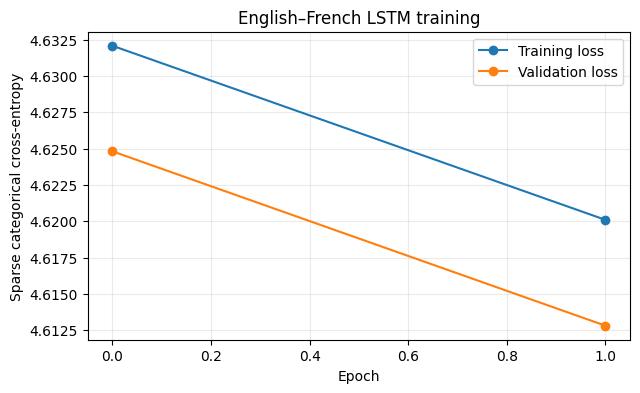

In [16]:
plt.figure(figsize=(7, 4))
plt.plot(history.history["loss"], marker="o", label="Training loss")
plt.plot(history.history["val_loss"], marker="o", label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Sparse categorical cross-entropy")
plt.title("English–French LSTM training")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

### 2.7 Test-set evaluation

In [17]:
loss = model.evaluate([x_test, d_test], y_test, sample_weight=w_test, verbose=0)
predicted_probabilities = model.predict([x_test, d_test], batch_size=BATCH_SIZE, verbose=0)
predicted_ids = np.argmax(predicted_probabilities, axis=-1)
valid_positions = y_test != PAD
masked_accuracy = (predicted_ids[valid_positions] == y_test[valid_positions]).mean()
print("Dataset:", dataset_source)
print(f"Masked test loss: {float(loss):.4f}")
print(f"Masked next-token accuracy (teacher forced): {float(masked_accuracy):.2%}")

Dataset: BUILT-IN DEMO
Masked test loss: 4.6141
Masked next-token accuracy (teacher forced): 24.24%


### 2.8 Translation function (inference)

In [18]:
def detokenize(words):
    text = " ".join(words)
    text = re.sub(r"\s+([.,!?;:])", r"\1", text)
    text = text.replace(" ' ", "'").replace(" ’ ", "’")
    return text.strip()


def translate_sentence(sentence, trained_model=model):
    encoded = pad_post([encode_sentence(sentence, source_vocab, add_eos=True)], SOURCE_LENGTH)
    decoder = np.zeros((1, TARGET_LENGTH), dtype=np.int32)
    decoder[0, 0] = SOS
    words = []
    for step in range(TARGET_LENGTH):
        probabilities = trained_model.predict([encoded, decoder], verbose=0)
        next_id = int(np.argmax(probabilities[0, step]))
        if next_id in (EOS, PAD):
            break
        words.append(target_id_to_word.get(next_id, "<unk>"))
        if step + 1 < TARGET_LENGTH:
            decoder[0, step + 1] = next_id
    return detokenize(words)

print("Example translation:")
for sentence in ["How are you?", "The product is available.", "Where is my order?"]:
    print(f"English: {sentence}\nFrench (model): {translate_sentence(sentence)}\n")

Example translation:
English: How are you?
French (model): 

English: The product is available.
French (model): est



English: Where is my order?
French (model): est



### 2.9 E-commerce examples

In [19]:
shopping_examples = [
    "What is the price?",
    "The order is ready.",
    "Delivery is free.",
]
results = pd.DataFrame({
    "English": shopping_examples,
    "Generated French": [translate_sentence(sentence) for sentence in shopping_examples],
})
print(results.to_string(index=False))

            English Generated French
 What is the price?              est
The order is ready.        est j j j
  Delivery is free.        est j j j


### Conclusion

- **Task 1:** learned embedding vectors represent input tokens; the encoder captures English context; the decoder generates French tokens; softmax provides vocabulary probabilities.
- **Task 2:** a complete bilingual preprocessing → LSTM training → test evaluation → English-to-French prediction workflow is implemented.
- **Important limitation:** a tiny offline sample is not sufficient for high-quality machine translation. Evaluate with the real Kaggle dataset for a meaningful result. New/unseen words may produce `<unk>` and short demos may produce repetitive translations.